# **Phase 2 - Transfer Learning & Data Augmentations**

Please follow the notebook in order. Make sure to add code where indicated by `''' TODO '''` or `# YOUR CODE HERE`. Please answer all questions indicated with '❓', and answer where it says 'ANSWER HERE'.

Ensure your notebook is easy to follow. All written report answers should be provided in the notebook itself.

In [1]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import time
import os
import copy

import matplotlib.pyplot as plt
import numpy as np
import torchvision

## **Overview**
1. CIFAR10 Dataset
2. Data Augmentations
3. Transfer learning with ResNet Architecture
4. Training ResNet Architecture

# **1. CIFAR10 Dataset**

This is an RGB dataset with 10 classes:

*plane, car, bird, cat, deer, dog, frog, horse, ship, truck*


## **1.1 Download and Load CIFAR10**

You can find CIFAR10 in ```torchvision.datasets.CIFAR10()``` or see [here](https://pytorch.org/vision/0.15/generated/torchvision.datasets.CIFAR10.html#torchvision.datasets.CIFAR10). Please Download the dataset and use Dataloaders to load it. This is identical to loading MNIST.

In [3]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 64

# Training set
train_set = torchvision.datasets.CIFAR10(root='./data', train=True,
                                         download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size,
                                           shuffle=True, num_workers=2)

# Test set
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
test_loader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                          shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

## **1.2 Display CIFAR10 Images**

Similar to Phase 1, please complete `show_imgs()` function to display 10 images. However, this time we want to display exactly one image per class. There are 10 classes total. Show a random image per class with their label.

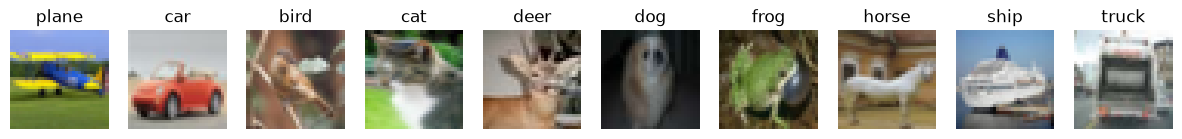

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def show_imgs(dataloader, classes):
    # Collect the first image seen for each class (the loader is shuffled, so this is random)
    found = {}
    for images, labels in dataloader:
        for img, lbl in zip(images, labels):
            l = lbl.item()
            if l not in found:
                found[l] = img
            if len(found) == len(classes):
                break
        if len(found) == len(classes):
            break

    fig, axes = plt.subplots(1, len(classes), figsize=(15, 2))
    for i in range(len(classes)):
        img = found[i] * 0.5 + 0.5          # undo Normalize
        axes[i].imshow(img.permute(1, 2, 0).numpy().clip(0, 1))
        axes[i].set_title(classes[i])
        axes[i].axis('off')
    plt.show()

show_imgs(train_loader, classes)

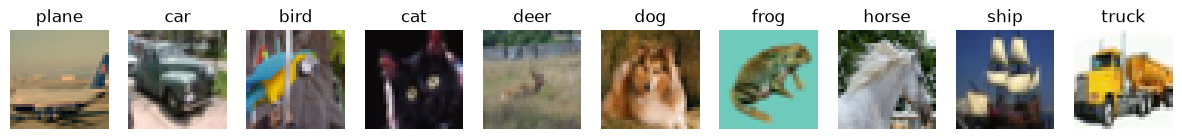

In [5]:
show_imgs(train_loader, classes)

# **2. Data Augmentations**

## **2.1 Use Built-in Augmentations**

Use augmentations from the `torchvision.transforms` library [
link](https://pytorch.org/vision/0.9/transforms.html). Apply the following. For the parameters, please test and choose suitable ones.


*   Horizontal Flip
*   Random Crop
*   Color Jitter
*   Random Resized Crop

Try each of these individually and display the augmented images using your `show_imgs()` function.

In [6]:
norm = transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))

def make_loader(aug_transform):
    ds = torchvision.datasets.CIFAR10(root='./data', train=True,
                                      download=False, transform=aug_transform)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=True, num_workers=2)

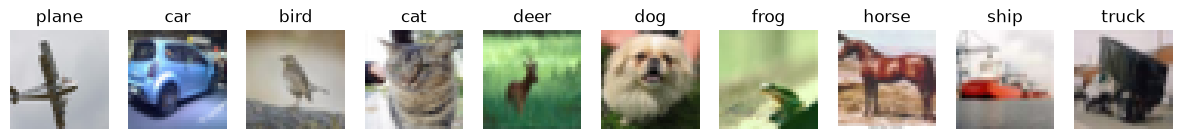

In [7]:
# Horizontal Flip
aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(), norm])
train_aug_loader = make_loader(aug_transform)
show_imgs(train_aug_loader, classes)

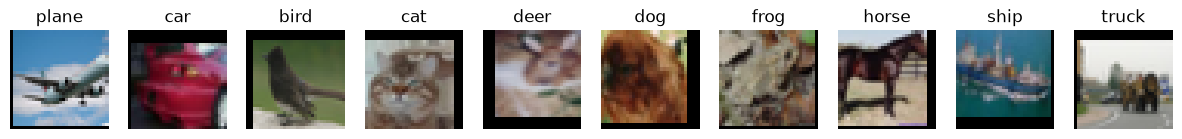

In [8]:
# Random Crop
aug_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(), norm])
train_aug_loader = make_loader(aug_transform)
show_imgs(train_aug_loader, classes)

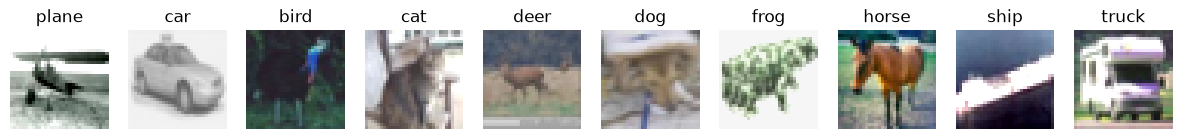

In [9]:
# Color Jitter
aug_transform = transforms.Compose([
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    transforms.ToTensor(), norm])
train_aug_loader = make_loader(aug_transform)
show_imgs(train_aug_loader, classes)

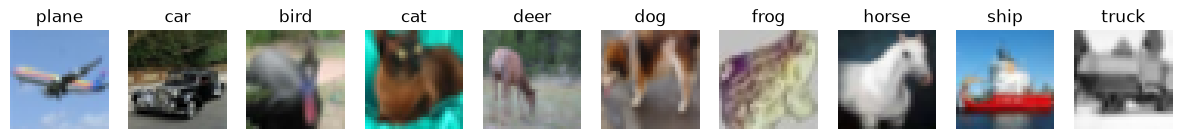

In [10]:
# Random Resized Crop
aug_transform = transforms.Compose([
    transforms.RandomResizedCrop(32, scale=(0.6, 1.0)),
    transforms.ToTensor(), norm])
train_aug_loader = make_loader(aug_transform)
show_imgs(train_aug_loader, classes)

### ❓ **Q 2.1.1 Please explain what Data augmentations are and their use. What is the purpose of making them random?**

ANSWER HERE

___
### ❓ **Q 2.1.2 Please explain all of the augmentations you are using. What is the value of each of them?**

ANSWER HERE

## **2.2 Custom Augmentations**

Create a custom data augmentation function. Please do rotation, randomly between -30 and 30 degrees. You must code this yourself, do not use the torchvision function.

[This tutorial ](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html) may be useful. You can use `PIL` image manupilation libraries, but NOT torchvision ones. Do not import any other libraries. You should only need:



```
from PIL import Image
import random
```





Apply this custom augmentation to the images and display the results using `show_imgs()`.

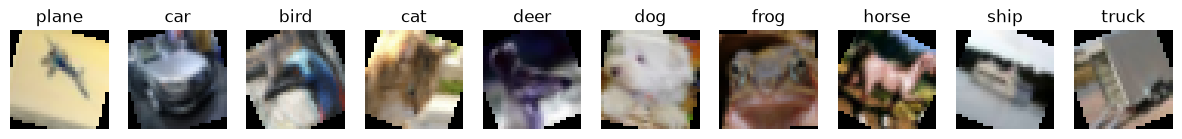

In [11]:
from PIL import Image
import random

class RandomRotate:
    def __init__(self, low=-30, high=30):
        self.low = low
        self.high = high

    def __call__(self, img):
        # img is a PIL image here, because the dataset applies this before ToTensor
        angle = random.uniform(self.low, self.high)
        return img.rotate(angle, resample=Image.BILINEAR)
    
# Apply Transform
rotate_transform = transforms.Compose([
    RandomRotate(-30, 30),
    transforms.ToTensor(),
    norm])

train_loader_rotate = make_loader(rotate_transform)

# Display images with the custom augmentation
show_imgs(train_loader_rotate, classes)

### ❓ **Q 2.2.1 Explain how you would determine what is a good lower and upper limit for rotation? We use -30 to 30, why does that make sense?**

ANSWER HERE

____

# **3. Transfer Learning**
Load ResNet18 model from ```torchvision.models.resnet18()```, make sure to load pretrained model with [weights](https://pytorch.org/vision/stable/models.html).
You will need to modify the final layer. ResNet outputs 100 labels - please change to the correct output dimension.

In [12]:
from torchvision.models import resnet18, ResNet18_Weights

## **3.1 ResNet18**

In [14]:
from torchvision.models import resnet18, ResNet18_Weights

# Instantiate Pretrained ResNet18
resnet18 = resnet18(weights=ResNet18_Weights.DEFAULT)

# Modify final layer CIFAR-10 has 10 classes
resnet18.fc = nn.Linear(resnet18.fc.in_features, 10)

# Load onto GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
resnet18 = resnet18.to(device)

# View Model to validate
print(resnet18)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## **3.2 Train ResNet on CIFAR10**

### **3.2.1 Train and Test Functions**
You can refer to Phase_1.ipynb to complete these functions. In ```train()```, rather than saving the accuracy and loss per iteration, you will need to save the loss and accuracy ***per epoch***. Plot loss and accuracy plots for both train and validation sets.

In [16]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += y.size(0)
    return running_loss / total, correct / total

def test_accuracy(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            running_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
    return running_loss / total, correct / total

def train(model, train_loader, test_loader, criterion, optimizer, device, num_epochs):
    # Saves loss and accuracy once per epoch
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    for epoch in range(num_epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        te_loss, te_acc = test_accuracy(model, test_loader, criterion, device)
        for k, v in zip(history, [tr_loss, tr_acc, te_loss, te_acc]):
            history[k].append(v)
        print(f"Epoch {epoch+1}/{num_epochs} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
              f"| test loss {te_loss:.3f} acc {te_acc:.3f}")
    return history

def plot_learning_curve(history):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(epochs, history['train_loss'], label='train')
    ax[0].plot(epochs, history['test_loss'], label='test')
    ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(epochs, history['train_acc'], label='train')
    ax[1].plot(epochs, history['test_acc'], label='test')
    ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.show()

### **3.2.2 Train and Plot Learning Curves**

Retrain the ResNet18 on CIFAR10 Dataset. You can chose the optimizer and loss function. Train first with then without data augmentation to compare. When using data augmentations, you can choose which augmentations to use!

Epoch 1/10 | train loss 1.056 acc 0.650 | test loss 0.876 acc 0.706
Epoch 2/10 | train loss 0.681 acc 0.769 | test loss 0.712 acc 0.765
Epoch 3/10 | train loss 0.496 acc 0.831 | test loss 0.605 acc 0.793
Epoch 4/10 | train loss 0.401 acc 0.863 | test loss 0.627 acc 0.799
Epoch 5/10 | train loss 0.319 acc 0.890 | test loss 0.584 acc 0.816
Epoch 6/10 | train loss 0.261 acc 0.911 | test loss 0.640 acc 0.807
Epoch 7/10 | train loss 0.242 acc 0.916 | test loss 0.656 acc 0.807
Epoch 8/10 | train loss 0.176 acc 0.940 | test loss 0.669 acc 0.812
Epoch 9/10 | train loss 0.140 acc 0.951 | test loss 0.716 acc 0.811
Epoch 10/10 | train loss 0.121 acc 0.958 | test loss 0.734 acc 0.810


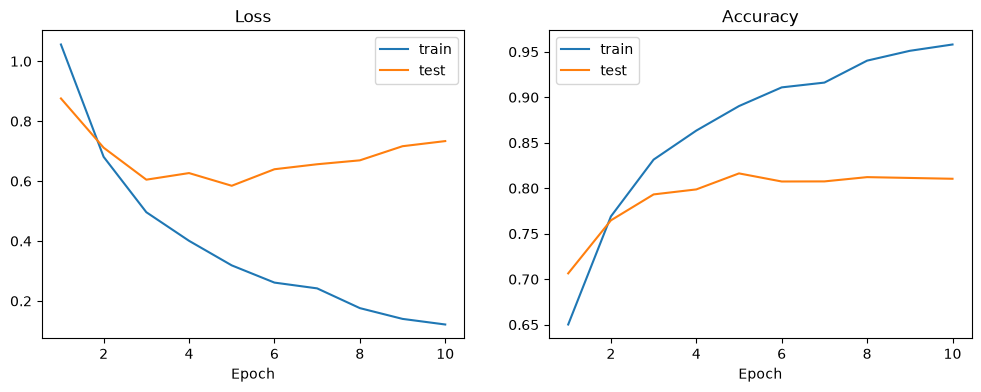

Test accuracy (no augmentation): 0.810


In [17]:
# Number of full passes over the training data
num_epochs = 10

# Loss function: CrossEntropyLoss applies softmax internally, so the model outputs raw scores (logits)
criterion = nn.CrossEntropyLoss()

# Optimizer: SGD updates all weights of resnet18 with a learning rate of 0.01.
# momentum=0.9 keeps a running average of past gradients, which smooths and speeds up training
optimizer = torch.optim.SGD(resnet18.parameters(), lr=0.01, momentum=0.9)

# Train on the non-augmented training set, testing after each epoch.
# Returns a dict with the per-epoch train/test loss and accuracy
hist_noaug = train(resnet18, train_loader, test_loader, criterion, optimizer, device, num_epochs)

# Plot the loss and accuracy curves for train and test
plot_learning_curve(hist_noaug)

# Compute final loss and accuracy on the test set with the trained model
test_loss, test_acc = test_accuracy(resnet18, test_loader, criterion, device)
print(f"Test accuracy (no augmentation): {test_acc:.3f}")

Epoch 1/10 | train loss 1.177 acc 0.601 | test loss 0.930 acc 0.698
Epoch 2/10 | train loss 0.834 acc 0.718 | test loss 0.684 acc 0.761
Epoch 3/10 | train loss 0.723 acc 0.755 | test loss 0.636 acc 0.779
Epoch 4/10 | train loss 0.671 acc 0.773 | test loss 0.588 acc 0.799
Epoch 5/10 | train loss 0.599 acc 0.793 | test loss 0.586 acc 0.802
Epoch 6/10 | train loss 0.577 acc 0.803 | test loss 0.563 acc 0.810
Epoch 7/10 | train loss 0.533 acc 0.815 | test loss 0.536 acc 0.822
Epoch 8/10 | train loss 0.505 acc 0.826 | test loss 0.562 acc 0.811
Epoch 9/10 | train loss 0.485 acc 0.832 | test loss 0.512 acc 0.825
Epoch 10/10 | train loss 0.461 acc 0.839 | test loss 0.488 acc 0.835


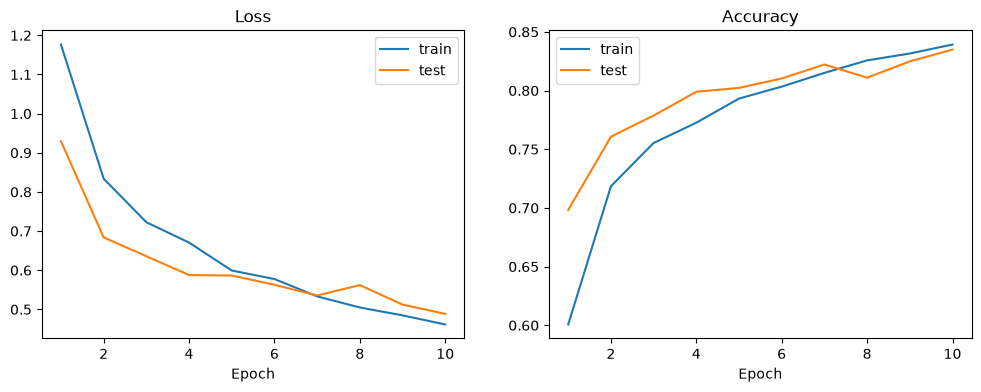

Test accuracy (with augmentation): 0.835


In [18]:
## TRAINING WITH AUGMENTATIONS

# Define Parameters
num_epochs = 10
aug_train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(), norm])
train_loader_aug = make_loader(aug_train_transform)

resnet18_aug = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet18_aug.fc = nn.Linear(resnet18_aug.fc.in_features, 10)
resnet18_aug = resnet18_aug.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(resnet18_aug.parameters(), lr=0.01, momentum=0.9)
hist_aug = train(resnet18_aug, train_loader_aug, test_loader, criterion, optimizer, device, num_epochs)
plot_learning_curve(hist_aug)
test_loss, test_acc = test_accuracy(resnet18_aug, test_loader, criterion, device)
print(f"Test accuracy (with augmentation): {test_acc:.3f}")

### **3.2.3 Confusion Matrix**

Write code to plot a confusion matrix after training the above ResNet18. Please make sure the axis have class names (defined in Section 1)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusion_matrix(model, loader, classes, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device))
            all_preds.extend(out.argmax(1).cpu().numpy())
            all_labels.extend(y.numpy())
    cm = confusion_matrix(all_labels, all_preds)
    disp = ConfusionMatrixDisplay(cm, display_labels=classes)
    fig, ax = plt.subplots(figsize=(8, 8))
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
    plt.show()

plot_confusion_matrix(resnet18, test_loader, classes, device)

## **3.2.4 Freeze Network**

Initialize a new ResNet18, Freeze all the non-linear or non-fc weights. Hence, we will only be training the fc layers.

Freezing implies setting `requires_grad = False` for selected parameters


In [ ]:
# Instantiate Pretrained ResNet18

resnet18_frz = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet18_frz.fc = nn.Linear(resnet18_frz.fc.in_features, 10)

for name, p in resnet18_frz.named_parameters():
    p.requires_grad = name.startswith('fc')

resnet18_frz = resnet18_frz.to(device)
print(resnet18_frz)
print("Trainable params:", sum(p.numel() for p in resnet18_frz.parameters() if p.requires_grad))

### **3.2.5 Train frozen ResNet18**

Retrain the frozen ResNet18 now with the same setup as the previous ResNet18 (same batch size, optimizer, learning rate, etc.) for direct comparison. The results may not be as good that is expected.

In [ ]:
## TRAINING WITH or WITHOUT AUGMENTATIONS

num_epochs = 10
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(filter(lambda p: p.requires_grad, resnet18_frz.parameters()),
                            lr=0.01, momentum=0.9)

hist_frz = train(resnet18_frz, train_loader, test_loader, criterion, optimizer, device, num_epochs)
plot_learning_curve(hist_frz)
test_loss, test_acc = test_accuracy(resnet18_frz, test_loader, criterion, device)
print(f"Test accuracy (frozen): {test_acc:.3f}")

### ❓ **Q 3.2.6 What was the difference when training with and without data augmentations?**

ANSWER HERE

___
### ❓ **Q 3.2.7 What is transfer learning and why would it be useful?**

ANSWER HERE

___
### ❓ **Q 3.2.8 What was the difference between freezing layers and retraining all? Explain in terms of classification metrics and why you saw such metrics and confusuon matrix. Is what you say as expected?**

ANSWER HERE

___
### ❓ **Q 3.2.9 For a pretrained model like ResNet, in what general scenarios would you (1) freeze your pretrained weights adn retrain last layer, (2) retrain entire architecture, and (3) Freeze all convolution layer weights and retrain all FC layers? Explain with example scenarios if possible.**

ANSWER HERE

___


### **3.2.10 Train frozen ResNet18 for better performance**

You may have noticed only training just the fc layer did not yield good performance. Now, you must try to investigate trying to freeze as much of the original model as possible for best results.


*   Keep fc layer unfrozen, and unfreeze the last block (in layer4 of resnet18)
*   You pick which layers to unfreeze!

Investigate the maximize the layers to unfreeze to yield best balance between performance to training time.

In [ ]:
# Instantiate Pretrained ResNet18
resnet18_frz = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet18_frz.fc = nn.Linear(resnet18_frz.fc.in_features, 10)

# Unfreeze the last block (in layer4 of resnet18).
# Everything is frozen first, then layer4 and fc are switched back on.
for name, p in resnet18_frz.named_parameters():
    p.requires_grad = name.startswith(('layer4', 'fc'))

resnet18_frz = resnet18_frz.to(device)

## TRAINING WITH or WITHOUT AUGMENTATIONS
# Define Parameters
num_epochs = 10
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(filter(lambda p: p.requires_grad, resnet18_frz.parameters()),
                            lr=0.01, momentum=0.9)

# Train the model, timing it for the comparison in Q 3.2.11
start = time.time()
hist_l4 = train(resnet18_frz, train_loader_aug, test_loader, criterion, optimizer, device, num_epochs)
print(f"Training time: {time.time() - start:.1f}s")

# Plot the learning curve
plot_learning_curve(hist_l4)

# Evaluate on Test Set
test_loss, test_acc = test_accuracy(resnet18_frz, test_loader, criterion, device)
print(f"Test accuracy (layer4 + fc unfrozen): {test_acc:.3f}")

In [ ]:
# Instantiate Pretrained ResNet18
resnet18_frz = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet18_frz.fc = nn.Linear(resnet18_frz.fc.in_features, 10)

# Freeze whichever layers you choose for best performance.
# Here layer3, layer4 and fc are trainable; conv1, bn1, layer1 and layer2 stay frozen.
for name, p in resnet18_frz.named_parameters():
    p.requires_grad = name.startswith(('layer3', 'layer4', 'fc'))

resnet18_frz = resnet18_frz.to(device)

## TRAINING WITH or WITHOUT AUGMENTATIONS
# Define Parameters
num_epochs = 10
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(filter(lambda p: p.requires_grad, resnet18_frz.parameters()),
                            lr=0.01, momentum=0.9)

# Train the model, timing it
start = time.time()
hist_frz2 = train(resnet18_frz, train_loader_aug, test_loader, criterion, optimizer, device, num_epochs)
print(f"Training time: {time.time() - start:.1f}s")

# Plot the learning curve
plot_learning_curve(hist_frz2)

# Evaluate on Test Set
test_loss, test_acc = test_accuracy(resnet18_frz, test_loader, criterion, device)
print(f"Test accuracy (layer3 + layer4 + fc unfrozen): {test_acc:.3f}")


### ❓ **Q 3.2.11 Which layers did you freeze to yield the best performance vs training time balance? Can you give any intuition as to why this worked well? Compare it with unfreezing only the fc layer and explain why it performs better.**

ANSWER HERE

___
___
# End of Phase 2 😊🥳